In [3]:

import pandas as pd
from pathlib import Path

root = Path.cwd()
if not (root / "data" / "lake" / "bronze").exists():
    root = root.parent

B = root / "data" / "lake" / "bronze"

books = pd.read_csv(B / "books.csv")
customers = pd.read_csv(B / "customers.csv")
orders = pd.read_csv(B / "orders.csv")
reviews = pd.read_csv(B / "reviews.csv")

print(len(books), len(customers), len(orders), len(reviews))



1000 515 3060 1200


In [4]:

def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes,
        "non_null": df.notna().sum(),
        "null_pct": (df.isna().mean() * 100).round(1),
        "unique": df.nunique(),
        "example": df.apply(
            lambda s: s.dropna().iloc[0] if s.notna().any() else None
        )
    })

profile(customers)


,dtype,non_null,null_pct,unique,example
customer_id,object,515,0.0,500,C0016
full_name,object,515,0.0,89,Ng Chee Keong
email,object,490,4.9,464,ng.chee.keong88@gmail.com
phone,object,515,0.0,500,017-7530810
mykad,object,515,0.0,500,720606-03-1611
state,object,515,0.0,22,Kelantan
signup_date,object,515,0.0,376,2025-12-09


In [5]:
profile(books)

,dtype,non_null,null_pct,unique,example
book_id,object,1000,0.0,1000,its-only-the-himalayas_981
title,object,1000,0.0,999,It's Only the Himalayas
category,object,1000,0.0,50,Travel
price_raw,object,1000,0.0,903,£45.17
rating_raw,object,1000,0.0,5,Two
availability,object,1000,0.0,1,In stock
url,object,1000,0.0,1000,https://books.toscrape.com/catalogue/its-only-...
ingested_at,object,1000,0.0,1,2026-11-02T02:11:55.965782+00:00


In [6]:
profile(orders)

,dtype,non_null,null_pct,unique,example
order_id,object,3060,0.0,3000,O00001
customer_id,object,3060,0.0,532,C0454
book_id,object,3060,0.0,948,life_104
quantity,int64,3060,0.0,5,1
order_date,object,3060,0.0,319,2026-07-23


In [7]:
profile(reviews)

,dtype,non_null,null_pct,unique,example
review_id,object,1200,0.0,1200,R00001
customer_id,object,1200,0.0,456,C0390
book_id,object,1200,0.0,678,the-lonely-city-adventures-in-the-art-of-being...
stars,int64,1200,0.0,5,2
review_text,object,1163,3.1,223,No response when I asked for a refund. Deliver...
review_date,object,1200,0.0,237,2026-05-19


In [8]:

# Step 2: Targeted data quality checks

checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
    "orders: date not YYYY-MM-DD": pd.to_datetime(
        orders["order_date"], format="%Y-%m-%d", errors="coerce"
    ).isna().sum(),
    "orders: unknown customer_id": (
        ~orders["customer_id"].isin(customers["customer_id"])
    ).sum(),
    "orders: unknown book_id": (
        ~orders["book_id"].isin(books["book_id"])
    ).sum(),
    "reviews: missing review_text": reviews["review_text"].isna().sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False
    ).sum()
}

pd.Series(checks, name="issues_found").to_frame()


,issues_found
customers: duplicate rows,15
customers: missing email,25
orders: duplicate order_id,60
orders: quantity <= 0,30
orders: date not YYYY-MM-DD,97
orders: unknown customer_id,35
orders: unknown book_id,0
reviews: missing review_text,37
reviews: phone number in text,19


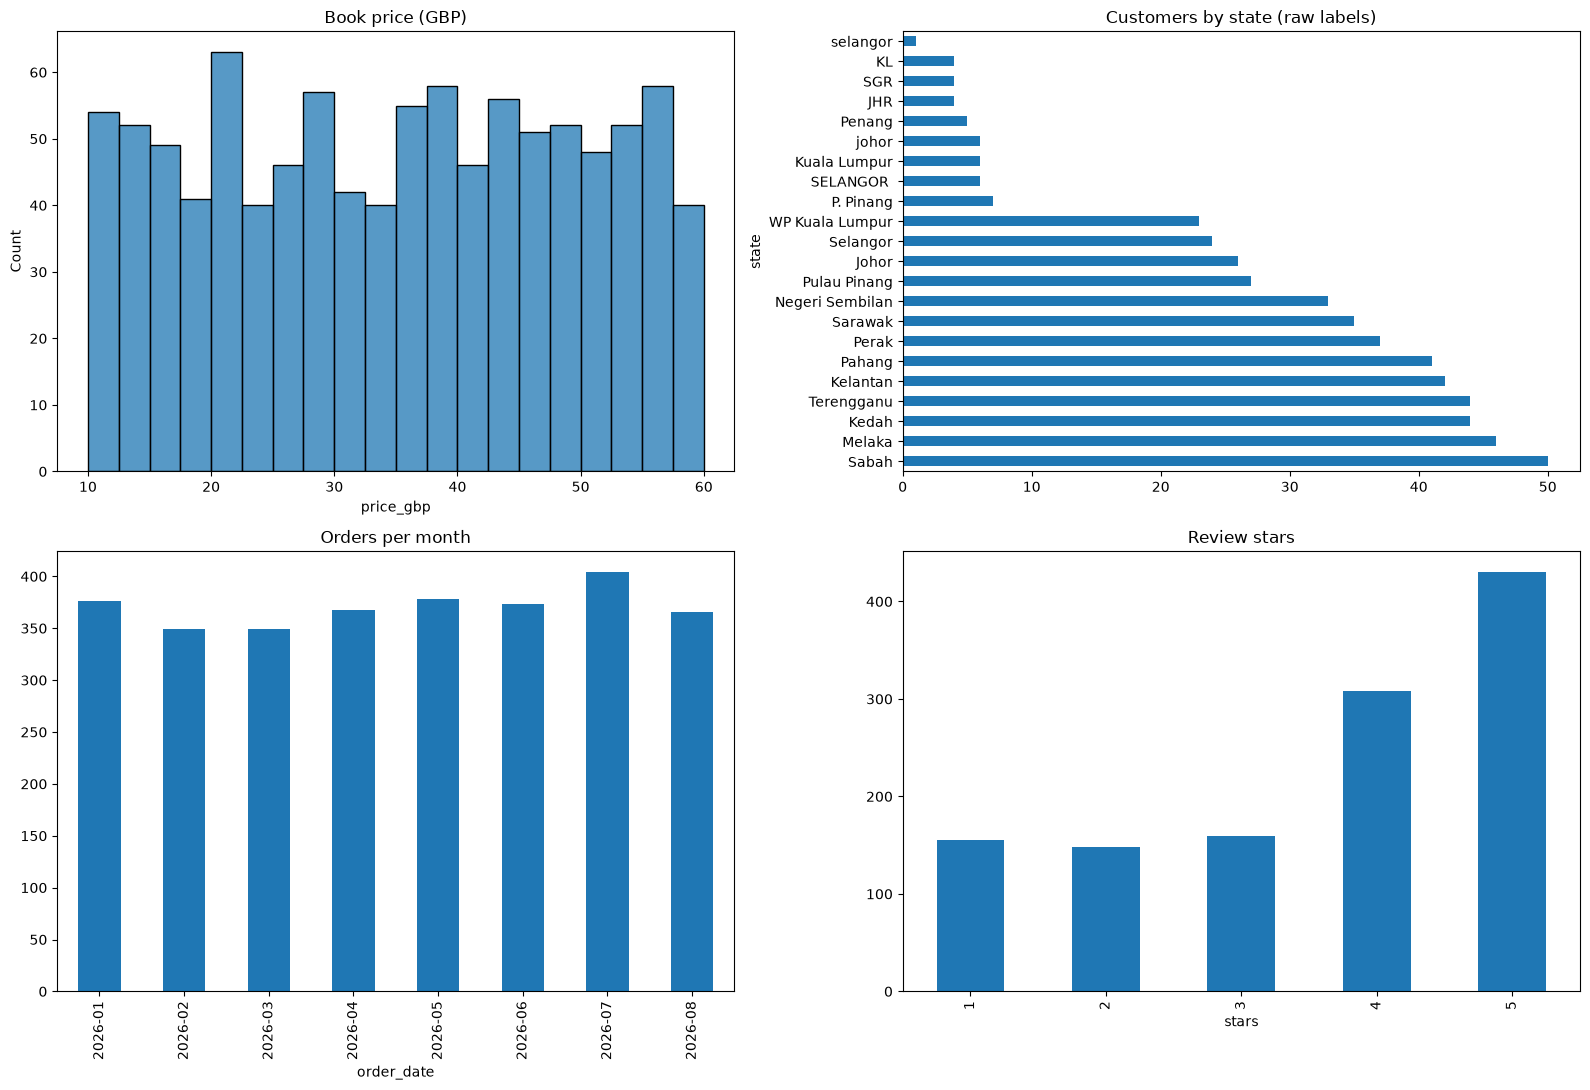

In [9]:

# Step 3: Draw four charts

import matplotlib.pyplot as plt
import seaborn as sns

# Convert price text to numbers for the chart only
books["price_gbp"] = pd.to_numeric(
    books["price_raw"].astype(str).str.replace(
        r"[^0-9.]", "", regex=True
    ),
    errors="coerce"
)

# Convert order dates
orders_ok = orders.assign(
    order_date=pd.to_datetime(
        orders["order_date"],
        format="%Y-%m-%d",
        errors="coerce"
    )
)

# Create four charts
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(
    books["price_gbp"],
    bins=20,
    ax=axes[0, 0]
).set_title("Book price (GBP)")

customers["state"].value_counts().plot.barh(
    ax=axes[0, 1],
    title="Customers by state (raw labels)"
)

orders_ok.groupby(
    orders_ok["order_date"].dt.to_period("M")
).size().plot.bar(
    ax=axes[1, 0],
    title="Orders per month"
)

reviews["stars"].value_counts().sort_index().plot.bar(
    ax=axes[1, 1],
    title="Review stars"
)

plt.tight_layout()
plt.show()


### Step 3: Chart Observations

**Chart 1 – Book Price (GBP)**

Book prices are spread across about £10 to £60, with no clear concentration in one price range.

**Chart 2 – Customers by State**

Sabah has the most customers, but some states have different names, such as Selangor, SELANGOR and SGR.

**Chart 3 – Orders per Month**

Orders are quite similar across the months, but July has the highest number of orders.

**Chart 4 – Review Stars**

Most reviews have 4 or 5 stars, so the ratings are more positive than negative.

### Step 4: Data Quality Report

| Dimension | Table.column | Check | Issues found | Fix planned for Lab 5 |
|---|---|---|---|---|
| Uniqueness | customers | Duplicate rows | 15 | Remove exact duplicates |
| Completeness | customers.email | Missing values | 25 | Check and handle missing emails |
| Uniqueness | orders.order_id | Duplicate IDs | 60 | Check duplicates and keep valid records |
| Validity | orders.quantity | Quantity <= 0 | 30 | Remove or correct invalid quantities |
| Validity | orders.order_date | Invalid date format | 97 | Convert dates to one standard format |
| Integrity | orders.customer_id | Unknown customer | 35 | Check and handle unknown customer IDs |
| Integrity | orders.book_id | Unknown book | 0 | No fix needed |
| Completeness | reviews.review_text | Missing values | 37 | Handle missing review text |
| Privacy | reviews.review_text | Phone number in text | 19 | Mask phone numbers |
| Consistency | customers.state | Different names for the same state | 22 distinct labels, not 22 errors | Standardise state names |
| Privacy | customers | Personal information present | PII columns present | Mask or protect personal data |

### Personal Data

The customers table contains personal data such as names, emails, phone numbers and MyKad numbers. MyKad is the most sensitive because it can identify a person. We also found 19 reviews that contain phone numbers. We should protect this information and mask it when needed.

### Bias Risk

Most reviews have 4 or 5 stars. If KedaiBuku only uses these ratings to promote books, the results may be biased towards books with positive reviews. Some states also have fewer customers, so their opinions may not be well represented. We should consider this when analysing the data.